# 숫자 2.5가 어떻게 기울기 -7과 -10이 될까?

NumPy 배열에 계산 그래프를 붙인 Tensor로 **두 표본의 예측 → 평균 제곱 오차 → 역전파 → SGD 한 번**을
끝까지 따라간다. 손계산을 먼저 하고 실제 `Linear`, `mse_loss`, 수치 미분과 대조한다.
AICE에서 본 손실·학습률 개념을 출발점으로 삼되, 고급 Python 문법은 전제하지 않는다.

A6-1에서 `uv sync --group dev` 후 `.venv`를 커널로 선택한다.
`uv run --group dev python tools/build_learning_notebook.py --execute`는 새 커널에서 전체 실행한다.
기본 계산·XOR는 다운로드 없이 실행된다. MNIST 부분은 캐시 네 파일이 있어야 하며,
없으면 `uv run python scripts/download_mnist.py`로 준비한다. 이 노트북은 다운로드하지 않는다.
기존 reports/figures는 읽어서 대조하며 저장하지 않는다.

[HTML](../study/a6-1.html)은 손계산·초기화 위젯용이다. JavaScript 난수열은 NumPy와 다르다.
이 노트북은 실제 Python 객체의 `.data`, `.grad`, `._prev`와 프레임워크 구현을 확인한다.

In [1]:
from pathlib import Path
import sys
import json
import platform
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'src/minigrad').is_dir(), 'A6-1 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(root / 'src'))
sys.path.insert(0, str(root / 'scripts'))
from minigrad import Tensor, nn, no_grad, optim
from minigrad.core.autograd import topological_order
from minigrad.gradcheck import check_gradients
from minigrad.data import DataLoader, load_mnist, xor_dataset
from minigrad.data.mnist import FILES, sha256
from train_xor import train_xor, first_epoch_below
import gradient_check
np.set_printoptions(precision=5, suppress=True)
print('Python', platform.python_version(), 'NumPy', np.__version__)

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(map(str, row)) + ' |')
    display(Markdown('\n'.join(lines)))

Python 3.12.13 NumPy 2.5.4


## 1. 첫 계산: 행은 표본, 열은 입력 특성

X는 (표본 2, 특성 2), W는 (입력 특성 2, 출력 1), b는 (출력 1,)이다.
정답 y는 (2,1)로 맞춘다. y를 (2,)로 주면 NumPy broadcasting으로 오차가 (2,2)가 되므로
다른 손실을 학습하게 된다. `requires_grad=False`인 입력도 W의 미분을 계산할 때 값이 필요하다.

In [2]:
X = Tensor([[1., 2.], [3., 4.]])
y = Tensor([[0.], [1.]])
W = nn.Parameter([[1.], [-1.]], name='W')
b = nn.Parameter([0.], name='b')
for name, value in [('X', X), ('y', y), ('W', W), ('b', b)]:
    print(name, 'shape=', value.shape, 'requires_grad=', value.requires_grad,
          'data=', value.data.tolist(), 'grad=', value.grad)

X shape= (2, 2) requires_grad= False data= [[1.0, 2.0], [3.0, 4.0]] grad= None
y shape= (2, 1) requires_grad= False data= [[0.0], [1.0]] grad= None
W shape= (2, 1) requires_grad= True data= [[1.0], [-1.0]] grad= None
b shape= (1,) requires_grad= True data= [0.0] grad= None


In [3]:
product = X @ W
pred = product + b
residual = pred - y
squared = residual ** 2
total = squared.sum()
loss = total / squared.size
for name, value in [('X@W', product), ('pred', pred), ('residual', residual),
                    ('squared', squared), ('total', total), ('loss', loss)]:
    print(name, 'shape=', value.shape, 'data=', value.data.tolist(), 'op=', value._op)
assert pred.shape == y.shape
np.testing.assert_allclose(pred.data, [[-1.], [-1.]])
assert loss.item() == 2.5
print('잘못된 shape 예: (pred - Tensor([0., 1.])).shape =', (pred - Tensor([0., 1.])).shape)

X@W shape= (2, 1) data= [[-1.0], [-1.0]] op= @
pred shape= (2, 1) data= [[-1.0], [-1.0]] op= +
residual shape= (2, 1) data= [[-1.0], [-2.0]] op= -
squared shape= (2, 1) data= [[1.0], [4.0]] op= **2
total shape= () data= 5.0 op= sum
loss shape= () data= 2.5 op= /
잘못된 shape 예: (pred - Tensor([0., 1.])).shape = (2, 2)


첫 행의 예측은 1×1 + 2×(-1) = -1, 둘째 행도 -1이다.
오차 [-1,-2]를 제곱한 [1,4]의 평균이 2.5다. 여기서 mean은 **표본과 출력의 모든 원소** 평균이다.
출력 3개라면 분모는 표본 수의 3배다. CrossEntropy는 클래스 손실을 먼저 합하고 표본 평균을 낸다.

## 2. 계산 그래프는 부모 객체를 기억한다

`_prev`는 이 값을 만드는 데 사용한 Tensor들의 튜플이다. `_backward`는 결과 grad를 읽어
부모 grad에 기여를 더하는 함수다. 밑줄 속성은 엔진을 공부할 때 관찰하며, 일반 학습 루프에서는 직접 호출하지 않는다.

In [4]:
named = [('X', X), ('y', y), ('W', W), ('b', b), ('product', product),
         ('pred', pred), ('residual', residual), ('squared', squared), ('total', total), ('loss', loss)]
names = {id(node): name for name, node in named}
order = topological_order(loss)
rows = []
for node in order:
    parents = []
    for parent in node._prev:
        parents.append(names.get(id(parent), 'constant ' + str(parent.data.tolist())))
    rows.append([names.get(id(node), 'constant'), node.shape, node._op or 'leaf', ', '.join(parents)])
table(['node', 'shape', 'operation', 'parents'], rows)
print('역전파 호출 순서:', ' → '.join(names.get(id(n), 'constant') for n in reversed(order)))

| node | shape | operation | parents |
| --- | --- | --- | --- |
| constant | () | leaf |  |
| y | (2, 1) | leaf |  |
| b | (1,) | leaf |  |
| W | (2, 1) | leaf |  |
| X | (2, 2) | leaf |  |
| product | (2, 1) | @ | X, W |
| pred | (2, 1) | + | product, b |
| residual | (2, 1) | - | pred, y |
| squared | (2, 1) | **2 | residual |
| total | () | sum | squared |
| loss | () | / | total, constant 2.0 |

역전파 호출 순서: loss → total → squared → residual → pred → product → X → W → b → y → constant


부모가 자식보다 앞에 오는 것이 위상 순서의 조건이다. 같은 단계의 형제 순서는 유일하지 않다.
backward는 이를 뒤집어 loss부터 실행한다. 그래야 한 노드로 들어오는 모든 경로의 기여를 모은 뒤 부모로 보낸다.

손계산: dL/dtotal=1/2 → dL/dsquared=[1/2,1/2] → dL/dresidual=[-1,-2].
뺄셈과 덧셈의 국소 미분은 1이므로 dL/dpred=[-1,-2]다.
dW=Xᵀ@dL/dpred=[[-7],[-10]], db=(-1)+(-2)=-3.
**b 하나가 두 행에 쓰였으므로 역전파는 행 축을 합친다. 평균을 두 번 내지 않는다.**

In [5]:
loss.backward()
for name, node in named:
    print(name, 'grad=', None if node.grad is None else node.grad.tolist())
manual_pred_grad = 2 * residual.data / residual.size
manual_W_grad = X.data.T @ manual_pred_grad
manual_b_grad = manual_pred_grad.sum(axis=0)
np.testing.assert_allclose(W.grad, manual_W_grad)
np.testing.assert_allclose(b.grad, manual_b_grad)
print('손계산 W, b:', manual_W_grad.tolist(), manual_b_grad.tolist())

X grad= None
y grad= None
W grad= [[-7.0], [-10.0]]
b grad= [-3.0]
product grad= [[-1.0], [-2.0]]
pred grad= [[-1.0], [-2.0]]
residual grad= [[-1.0], [-2.0]]
squared grad= [[0.5], [0.5]]
total grad= 0.5
loss grad= 1.0
손계산 W, b: [[-7.0], [-10.0]] [-3.0]


## 3. 같은 계산을 기존 레이어와 수치 미분으로 대조

수치 미분은 W의 각 원소를 ±ε 움직여 손실의 변화를 비교한다.
`check_gradients`는 검사 대상 grad를 지우고 새 그래프를 만들어 분석 미분을 계산한다.
같은 입력·가중치·손실로 비교해야 한다. ReLU의 꺾이는 점과 매번 바뀌는 Dropout 마스크에서는 비교 조건이 깨질 수 있다.

In [6]:
layer = nn.Linear(2, 1, init='zero')
layer.W.data[:] = W.data
layer.b.data[:] = b.data
np.testing.assert_allclose(layer(X).data, pred.data)
assert nn.mse_loss(layer(X), y).item() == loss.item()
checks = check_gradients(lambda: nn.mse_loss(layer(X), y), [layer.W, layer.b], ['W', 'b'])
for result in checks:
    print(result.line())
    assert result.passed
epsilon = 1e-5
original = layer.W.data[0, 0]
try:
    layer.W.data[0, 0] = original + epsilon
    plus = nn.mse_loss(layer(X), y).item()
    layer.W.data[0, 0] = original - epsilon
    minus = nn.mse_loss(layer(X), y).item()
finally:
    layer.W.data[0, 0] = original
print('W[0,0] ±ε loss:', plus, minus, '중심차분:', (plus-minus)/(2*epsilon))

[Pass] W                            Gradient Check - Analytic: -10.000000, Numerical: -10.000000, Diff: 8.7e-13
[Pass] b                            Gradient Check - Analytic: -3.000000, Numerical: -3.000000, Diff: 3.3e-12
W[0,0] ±ε loss: 2.4999300004999996 2.5000700004999996 중심차분: -7.000000000001449


## 4. SGD는 data를 바꾸고 zero_grad는 grad를 지운다

학습률 0.01에서 W=[1.07,-0.90], b=0.03이 된다. 이전 pred와 loss는 이미 계산한 값이다.
갱신 뒤의 예측·손실은 **새 순전파**로 계산한다. 갱신한 data로 이전 그래프를 역전파하면
순전파 때와 다른 값을 미분에 쓸 수 있다. 이 엔진에는 제자리 변경을 자동 감지하는 장치가 없다.

In [7]:
opt = optim.SGD(layer.parameters(), lr=.01)
before = nn.mse_loss(layer(X), y).item()
opt.step()
after_pred = layer(X)
after = nn.mse_loss(after_pred, y).item()
print('W:', layer.W.data.tolist(), 'b:', layer.b.data.tolist())
print('이전 예측:', pred.data.tolist(), '새 예측:', after_pred.data.tolist())
print('loss:', before, '→', after)
np.testing.assert_allclose(layer.W.data, [[1.07], [-.90]])
assert after < before
opt.zero_grad()
print('zero_grad 후:', layer.W.grad, layer.b.grad)
assert layer.W.grad is None and layer.b.grad is None

W: [[1.07], [-0.9]] b: [0.03]
이전 예측: [[-1.0], [-1.0]] 새 예측: [[-0.7], [-0.3599999999999999]]
loss: 2.5 → 1.1697999999999997
zero_grad 후: None None


## 5. 공유 노드와 두 종류의 누적

x=2, s=x×x, L=s×s+s이면 L=20, dL/ds=2s+1=9, dL/dx=9×(x+x)=36이다.
s는 그래프에서 한 번 방문하지만, 곱셈의 두 입력 자리에서 받은 기여는 둘 다 더한다.
호출 안의 경로 누적과 호출 사이의 리프 누적을 구별하자. 중간 노드 grad는 매 backward에서 새로 계산한다.
매개변수를 여러 배치에서 누적할 의도가 없다면 매 스텝 `opt.zero_grad()`를 호출한다.

In [8]:
x = Tensor(2., requires_grad=True)
s = x*x
shared_loss = s*s + s
shared_loss.backward()
print('첫 backward: loss, s.grad, x.grad =', shared_loss.item(), s.grad.item(), x.grad.item())
shared_loss.backward()
print('두 번째: s.grad, x.grad =', s.grad.item(), x.grad.item())
assert s.grad.item() == 9 and x.grad.item() == 72
x.zero_grad()
shared_loss.backward()
assert x.grad.item() == 36
print('리프 초기화 뒤 다시:', x.grad.item())

첫 backward: loss, s.grad, x.grad = 20.0 9.0 36.0
두 번째: s.grad, x.grad = 9.0 72.0
리프 초기화 뒤 다시: 36.0


## 6. 벡터·행렬 축과 loss reduction

`(3,) @ (3,)`은 shape `()`인 내적, `(N,3) @ (3,C)`는 `(N,C)`다.
행렬 역전파는 dA=G@Bᵀ, dB=Aᵀ@G이다. 배치가 방송되면 복제된 축의 기여를 합친다.
벡터 출력의 backward에는 같은 shape의 시작 기울기를 줘야 한다. 이는 각 출력에 곱할 가중치이며,
모든 출력에 대해 개별 야코비안을 만드는 동작은 아니다.

In [9]:
a = Tensor([1., 2., 3.], requires_grad=True)
c = Tensor([4., 5., 6.], requires_grad=True)
dot = a @ c
dot.backward()
print('내적:', dot.item(), 'shape:', dot.shape, 'da:', a.grad, 'dc:', c.grad)
np.testing.assert_allclose(a.grad, c.data)
vector = a * 2
try:
    vector.backward()
except RuntimeError as error:
    print(type(error).__name__, str(error))
a.zero_grad()
vector.backward([1., 0., -1.])
print('가중합의 da:', a.grad)
np.testing.assert_allclose(a.grad, [2., 0., -2.])

내적: 32.0 shape: () da: [4. 5. 6.] dc: [1. 2. 3.]
RuntimeError 스칼라가 아닌 텐서에서 backward()를 부르려면 grad를 넘겨야 한다
가중합의 da: [ 2.  0. -2.]


In [10]:
logits = Tensor([[1., 2., .5], [0., 0., 0.]], requires_grad=True)
labels = np.array([1, 2])
probabilities = logits.softmax().data
per_sample = -logits.log_softmax().data[np.arange(2), labels]
ce = nn.cross_entropy(logits, labels)
ce.backward()
print('각 표본 CE:', per_sample, '배치 평균:', ce.item())
print('확률 행 합:', probabilities.sum(axis=1), '로짓 grad 행 합:', logits.grad.sum(axis=1))
np.testing.assert_allclose(ce.item(), per_sample.mean())
np.testing.assert_allclose(logits.grad, (probabilities-nn.one_hot(labels, 3))/2)
np.testing.assert_allclose(logits.grad.sum(axis=1), 0, atol=1e-15)

각 표본 CE: [0.46437 1.09861] 배치 평균: 0.7814905363880273
확률 행 합: [1. 1.] 로짓 grad 행 합: [-0. -0.]


## 7. 기본을 XOR에 연결

XOR 입력은 (4,2), 정답은 (4,1)이다. 중간 Linear와 ReLU를 여러 번 연결해도 같은 엔진이 미분한다.
이 네 표본에서는 1 epoch=전체 배치 한 스텝이다. 학습에 사용한 네 입력의 정확도이며 일반화 평가가 아니다.
Zero는 모든 가중치와 편향이 0이라 ReLU에서 기울기가 막힌다. He는 분산을 조절하는 출발점이며 성공 보장은 아니다.

zero

 초기 loss= 0.6931471805599453 최종 loss= 0.6931471805599453 정확도= 0.5 loss<.1 epoch= None
입력 순서 [00,01,10,11]의 확률: [0.5 0.5 0.5 0.5]


he 초기 loss= 0.7136015886153977 최종 loss= 0.0019055374834025932 정확도= 1.0 loss<.1 epoch= 30
입력 순서 [00,01,10,11]의 확률: [0.00554 0.99919 0.99921 0.00047]


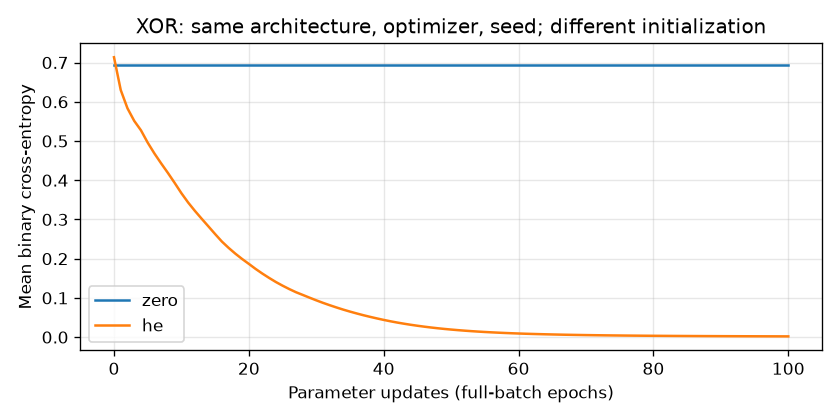

In [11]:
xor_results = {}
for method in ['zero', 'he']:
    losses, accuracies, model = train_xor(method, seed=0, epochs=100)
    xor_results[method] = (losses, accuracies, model)
    with no_grad():
        prob = model(Tensor(xor_dataset()[0])).data.ravel()
    print(method, '초기 loss=', losses[0], '최종 loss=', losses[-1],
          '정확도=', accuracies[-1], 'loss<.1 epoch=', first_epoch_below(losses))
    print('입력 순서 [00,01,10,11]의 확률:', prob)
assert np.ptp(xor_results['zero'][0]) == 0
assert xor_results['he'][0][-1] < .1
fig, ax = plt.subplots(figsize=(7, 3.5))
for method, (losses, _, _) in xor_results.items():
    ax.plot(np.arange(len(losses)), losses, label=method)
ax.set(xlabel='Parameter updates (full-batch epochs)', ylabel='Mean binary cross-entropy',
       title='XOR: same architecture, optimizer, seed; different initialization')
ax.legend()
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=120)
display(Image(data=image_buffer.getvalue()))
plt.close(fig)

가로축 0은 갱신 전이다. 곡선은 각 갱신 **후** 같은 네 입력에서 측정한 평균 BCE다.
정확도는 0.5 기준 이진 판정이라 손실과 같은 속도로 변하지 않는다.

## 8. MNIST: 동일한 루프, 더 많은 행과 출력 열

28×28 픽셀을 784개 특성으로 펼쳐 255로 나누며, 로짓 (배치,10)에 CrossEntropy를 쓴다.
아래는 캐시 SHA-256을 확인하고 seed 0, He, 784-128-10, SGD .1, batch 64로 **전체 train 1 epoch**를 실행한다.
Test는 10,000장의 정확도를 한 번 계산한다. 여기서는 하이퍼파라미터를 고르지 않는다.
한 epoch 결과나 반복해서 본 공개 Test가 새로운 데이터 성능을 보장하지 않는다.

In [12]:
mnist_dir = root / 'data/mnist'
missing = [name for name, _ in FILES.values() if not (mnist_dir/name).is_file()]
if missing:
    raise FileNotFoundError('먼저 scripts/download_mnist.py로 캐시를 준비하세요.')
for name, expected in FILES.values():
    assert sha256(mnist_dir/name) == expected, name
X_train, y_train, X_test, y_test = load_mnist(mnist_dir, download_if_missing=False)
print('train:', X_train.shape, y_train.shape, 'test:', X_test.shape, y_test.shape)
print('dtype:', X_train.dtype, y_train.dtype, '픽셀 범위:', X_train.min(), X_train.max())
rng = np.random.default_rng(0)
mnist_model = nn.mlp([784, 128, 10], init='he', rng=rng)
mnist_opt = optim.SGD(mnist_model.parameters(), lr=.1)
loader = DataLoader(X_train, y_train, batch_size=64, rng=rng)
first_loss = None
for step, (xb, yb) in enumerate(loader, start=1):
    batch_logits = mnist_model(Tensor(xb))
    batch_loss = nn.cross_entropy(batch_logits, yb)
    if step == 1:
        first_loss = batch_loss.item()
        print('첫 배치:', xb.shape, yb.shape, 'logits:', batch_logits.shape, 'loss:', first_loss)
    mnist_opt.zero_grad()
    batch_loss.backward()
    mnist_opt.step()
mnist_model.eval()
correct = 0
with no_grad():
    for start in range(0, len(X_test), 1000):
        test_logits = mnist_model(Tensor(X_test[start:start+1000])).data
        correct += int((test_logits.argmax(axis=1) == y_test[start:start+1000]).sum())
test_accuracy = correct/len(y_test)
previous = json.loads((root/'reports/train_mnist.json').read_text(encoding='utf-8'))
print('실행 step 수:', step, '마지막 배치:', xb.shape)
print('현재 Test 정확도:', test_accuracy, '기존 보고서:', previous['history'][0]['test_accuracy'])
assert previous['config'] == dict(epochs=1, batch_size=64, hidden=128, optimizer='sgd', lr=.1, init='he', seed=0)
assert test_accuracy >= .8
print('이 대조는 설정·캐시와 현재 1 epoch 실행에 한정된다. 다른 초기화/보너스 보고서는 재실행하지 않았다.')

train: (60000, 784) (60000,) test: (10000, 784) (10000,)
dtype: float64 int64 픽셀 범위: 0.0 1.0
첫 배치: (64, 784) (64,) logits: (64, 10) loss: 2.3895580592795973


실행 step 수: 938 마지막 배치: (32, 784)
현재 Test 정확도: 0.9376 기존 보고서: 0.9376
이 대조는 설정·캐시와 현재 1 epoch 실행에 한정된다. 다른 초기화/보너스 보고서는 재실행하지 않았다.


## 9. 확장: eval, no_grad, Dropout, L2는 서로 다른 경계

`eval()`은 하위 레이어의 training 상태를 바꾸고, `no_grad()`는 블록 안 새 연산의 그래프 기록을 끈다.
eval만 해도 Linear의 그래프는 만들어진다. no_grad만 해도 train 상태 Dropout은 계속 마스크를 뽑는다.
Inverted Dropout은 남긴 값을 1/(1-p)배 하므로 **기댓값**이 유지된다. 작은 표본의 평균이 매번 같지는 않다.

In [13]:
dropout = nn.Dropout(.5, rng=np.random.default_rng(7))
demo = nn.Sequential(nn.Linear(2, 2, rng=np.random.default_rng(0)), dropout)
demo.eval()
print('eval: model.training, dropout.training, graph=', demo.training, dropout.training, demo(X).requires_grad)
dropout.train()
ones = Tensor(np.ones(12), requires_grad=True)
with no_grad():
    masked = dropout(ones)
print('train + no_grad: data=', masked.data, 'graph=', masked.requires_grad)
dropout.eval()
print('eval Dropout은 입력 자체 반환:', dropout(ones) is ones)
assert not masked.requires_grad and set(np.unique(masked.data)).issubset({0., 2.})

# λ/2 * sum(p²)의 미분 λp를 optimizer가 grad에 더한다.
p = nn.Parameter([2.])
p.grad = np.array([0.])
decay = optim.SGD([p], lr=.1, weight_decay=.5)
decay.step()
print('L2만 있는 SGD: 2 - .1*(0 + .5*2) =', p.item(), '저장 grad=', p.grad)
np.testing.assert_allclose(p.data, [1.9])

eval: model.training, dropout.training, graph= False False True
train + no_grad: data= [2. 2. 2. 0. 0. 2. 0. 2. 2. 0. 0. 0.] graph= False
eval Dropout은 입력 자체 반환: True
L2만 있는 SGD: 2 - .1*(0 + .5*2) = 1.9 저장 grad= [0.]


L2는 이 구현에서 optimizer에 넘긴 **모든** 파라미터(편향 포함)에 적용된다.
grad=None이면 그 파라미터의 갱신과 감쇠를 건너뛴다. 저장된 `.grad`나 출력한 데이터 손실에 L2가 더해지지는 않는다.
Adam의 weight_decay도 기울기에 λp를 더하는 방식이며 AdamW와 다르다.
Dropout gradient check는 ±ε에서 같은 마스크를 써야 하고, 기대 평균만 비교해서 역전파를 검증할 수 없다.

## 10. 기존 gradient check와 실패 검출

상대 오차는 텐서 전체의 ‖분석-수치‖/(‖분석‖+‖수치‖)이다. 아래는 기존 스크립트의 사례를 실행하되 보고서를 덮어쓰지 않는다.
이 검사에 없는 모든 입력까지 정확함을 입증하지는 않는다.

In [14]:
gradient_check.rng = np.random.default_rng(2024)
results = []
for case, fn, tensors, tensor_names in gradient_check.build_cases():
    for result in check_gradients(fn, tensors, tensor_names):
        assert result.passed, result.line()
        results.append(result)
worst = max(results, key=lambda r: r.difference)
print('기존 사례:', len(results), '개 통과; 최대 상대 오차:', worst.difference, worst.name)
z = Tensor(3., requires_grad=True)
def wrong_loss():
    out = z._result(z.data**2, (z,), 'intentionally_wrong')
    def wrong_backward():
        z._accumulate(out.grad*z.data)  # 음성 대조: 정답 2z의 절반
    out._backward = wrong_backward
    return out
wrong = check_gradients(wrong_loss, [z], ['wrong derivative'])[0]
print(wrong.line())
assert not wrong.passed

기존 사례: 38 개 통과; 최대 상대 오차: 5.234648495473323e-11 CrossEntropyLoss.logits
[FAIL] wrong derivative             Gradient Check - Analytic:  3.000000, Numerical:  6.000000, Diff: 3.3e-01


## 친구에게 시연하기 / 스스로 답하기

1. 첫 두 행에서 예측 -1, 오차 -1/-2, 평균 손실 2.5를 직접 계산한다.
2. 그래프 표의 부모와 역전파 순서를 가리키며 W의 -7/-10과 b의 -3이 나온 이유를 말한다.
3. SGD 전후 data와 grad를 구별하고, 이전 loss가 저절로 변하지 않는 것을 보여 준다.
4. 공유 s가 한 번 방문돼도 두 기여를 받는 이유와 zero_grad의 역할을 설명한다.
5. XOR zero/he 곡선을 비교한다. 같은 seed 숫자가 HTML과 같은 가중치를 뜻하지 않는 이유를 말한다.
6. MNIST의 (64,784) → (64,10) → 스칼라를 연결하고 정확도와 손실의 차이를 설명한다.
7. 확장으로 eval/no_grad 차이와 L2가 실제로 더해지는 위치를 보여 준다.

**확인 질문:** y의 shape가 (2,)이면 무엇을 비교하는가? b의 grad를 평균 내면 왜 틀리는가?
mean을 sum으로 바꾸면 grad는 몇 배인가? 같은 그래프를 data 갱신 뒤 쓰면 왜 위험한가?
Gradient check가 통과해도 ReLU의 모든 꺾임과 새로운 데이터 성능까지 보장할 수 없는 이유는?

소스 연결: `core/tensor.py`의 `_result`, `_accumulate`, `unbroadcast`, `__matmul__`;
`core/autograd.py`의 `topological_order`, `backward`; `nn/layers.py`의 Linear/Dropout;
`nn/losses.py`의 reduction; `optim/optimizer.py`의 zero_grad/step.